# Chapter 3 — Methodology

**Ho Chi Minh City University of Technology · 2026**

---

## Table of Contents

| § | Topic | Figure |
|---|-------|--------|
| 3.1 | [Methodological Objective and Reproducibility](#31-methodological-objective-and-reproducibility) | Fig 3.1 |
| 3.2 | [Data Preparation and Feature Conditioning](#32-data-preparation-and-feature-conditioning) | Fig 3.2 |
| 3.3 | [Graph Construction and Markov Normalisation](#33-graph-construction-and-markov-normalisation) | Fig 3.3 |
| 3.4 | [Spectral Computation and Embedding Construction](#34-spectral-computation-and-embedding-construction) | Fig 3.4 |
| 3.5 | [Hyperparameter Strategy](#35-hyperparameter-strategy) | Fig 3.5 |
| 3.6 | [Comparative Evaluation Protocol](#36-comparative-evaluation-protocol) | — |
| 3.7 | [Computational Considerations](#37-computational-considerations) | — |

---

In [8]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy.linalg import eigh
from scipy.spatial.distance import cdist
from sklearn.datasets import make_swiss_roll, make_moons, make_s_curve
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ── Reproducibility ───────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Matplotlib global style ───────────────────────────────────────
matplotlib.rcParams.update({
    'font.family':      'serif',
    'font.size':        11,
    'axes.titlesize':   12,
    'axes.labelsize':   11,
    'xtick.labelsize':  9,
    'ytick.labelsize':  9,
    'legend.fontsize':  9,
    'figure.dpi':       120,
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'text.usetex':      False,   # always use matplotlib mathtext, never LaTeX subprocess
})

# ── Wong (2011) colour-blind-safe palette ─────────────────────────
CB = {
    'orange':    '#E69F00',
    'sky':       '#56B4E9',
    'green':     '#009E73',
    'yellow':    '#F0E442',
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'pink':      '#CC79A7',
    'black':     '#000000',
}

# ── Core diffusion-map helper ─────────────────────────────────────
def build_diffusion_map(X, epsilon, alpha=1.0, n_components=10):
    """
    Construct a diffusion map for data matrix X.

    Parameters
    ----------
    X           : (n, d) array of observations
    epsilon     : bandwidth of the Gaussian kernel
    alpha       : density normalisation exponent (0 = no correction, 1 = full)
    n_components: number of eigenpairs to retain

    Returns
    -------
    vals   : eigenvalues  (n_components,)
    psi    : eigenvectors (n, n_components)  — diffusion coordinates
    P      : Markov transition matrix (n, n)
    W      : raw Gaussian kernel matrix (n, n)
    W_tilde: anisotropically normalised kernel (n, n)
    eps    : the bandwidth used
    """
    D2   = cdist(X, X, 'sqeuclidean')
    W    = np.exp(-D2 / epsilon)

    # Anisotropic density normalisation (Coifman & Lafon 2006)
    q    = W.sum(axis=1)
    W_tilde = W / np.outer(q**alpha, q**alpha)

    # Row-normalise → Markov matrix
    row_sum = W_tilde.sum(axis=1)
    P       = W_tilde / row_sum[:, None]

    # Symmetric representation for stable eigen-decomposition
    d_sqrt  = np.sqrt(row_sum)
    M_sym   = W_tilde / np.outer(d_sqrt, d_sqrt)
    M_sym   = (M_sym + M_sym.T) / 2          # ensure exact symmetry

    n   = X.shape[0]
    k   = min(n_components + 1, n)
    vals, vecs = eigh(M_sym, subset_by_index=[n - k, n - 1])

    # Sort descending; recover P-eigenvectors
    idx  = np.argsort(vals)[::-1]
    vals = vals[idx]
    vecs = vecs[:, idx]
    psi  = vecs / d_sqrt[:, None]
    psi  = psi / psi[:, 0:1]                # normalise trivial mode to 1

    return vals[1:], psi[:, 1:], P, W, W_tilde, epsilon

print("Imports and helpers loaded.  SEED =", SEED)

Imports and helpers loaded.  SEED = 42


## 3.1 Methodological Objective and Reproducibility

This chapter translates the theoretical framework of Chapter 2 into a concrete, reproducible experimental protocol.  
The primary objective is to evaluate, on controlled synthetic datasets, whether the Diffusion Map algorithm captures intrinsic low-dimensional structure that may be less apparent to classical linear methods.

The full pipeline comprises five sequential stages:

1. **Data Preparation** — standardise features so that no coordinate dominates kernel distances.  
2. **Graph Construction** — form the Gaussian affinity matrix $W$, apply anisotropic density normalisation, and row-normalise to obtain a Markov operator $P$.  
3. **Spectral Computation** — factorise $P$ and retain the $m$ leading non-trivial eigenpairs.  
4. **Embedding** — assemble diffusion coordinates $\Psi_t$ and project data into $\mathbb{R}^m$.  
5. **Comparative Evaluation** — place results alongside PCA and t-SNE under identical conditions.

> **Reproducibility principle:** All experiments use a fixed random seed (`SEED = 42`).  
> Every figure is saved as a vector PDF at 300 dpi so that the printed thesis is pixel-exact with this notebook.

**Figure 3.1** below illustrates the end-to-end pipeline as a flow diagram.

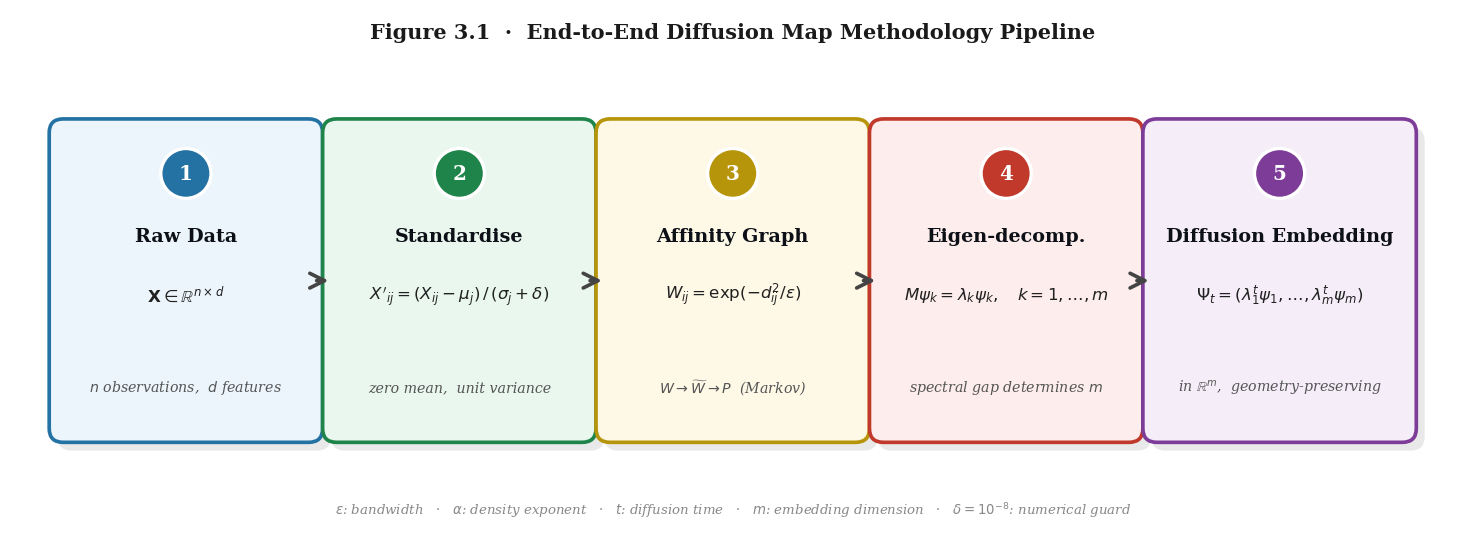

Saved: fig3_1_pipeline.pdf


In [9]:
# ── Fig 3.1 · Pipeline flow diagram — PhD thesis quality ─────────
# Uses matplotlib mathtext (no external LaTeX subprocess needed).

# ── Stage definitions ─────────────────────────────────────────────
stages = [
    dict(num='1', title='Raw Data',
         math=r'$\mathbf{X}\in\mathbb{R}^{n\times d}$',
         note=r'$n$ observations,  $d$ features',
         fc='#EBF5FB', ec='#2471A3'),
    dict(num='2', title='Standardise',
         math=r"$X'_{ij}=(X_{ij}-\mu_j)\,/\,(\sigma_j+\delta)$",
         note=r'zero mean,  unit variance',
         fc='#E9F7EF', ec='#1E8449'),
    dict(num='3', title='Affinity Graph',
         math=r'$W_{ij}=\exp(-d_{ij}^2/\varepsilon)$',
         note=r'$W \rightarrow \widetilde{W} \rightarrow P$  (Markov)',
         fc='#FEF9E7', ec='#B7950B'),
    dict(num='4', title='Eigen-decomp.',
         math=r'$M\psi_k=\lambda_k\psi_k,\quad k=1,\ldots,m$',
         note=r'spectral gap determines $m$',
         fc='#FDEDEC', ec='#C0392B'),
    dict(num='5', title='Diffusion Embedding',
         math=r'$\Psi_t=(\lambda_1^t\psi_1,\ldots,\lambda_m^t\psi_m)$',
         note=r'in $\mathbb{R}^m$,  geometry-preserving',
         fc='#F5EEF8', ec='#7D3C98'),
]

# ── Canvas ────────────────────────────────────────────────────────
fig_w, fig_h = 15.5, 5.6
fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_xlim(0, fig_w)
ax.set_ylim(0, fig_h)
ax.axis('off')
fig.patch.set_facecolor('white')

n   = len(stages)
lm  = 0.55                                # left/right margin
gap = 0.30                                # gap between boxes
bw  = (fig_w - 2*lm - gap*(n - 1)) / n   # box width  ≈ 2.61
bh  = 3.20                                # box height
cy  = fig_h * 0.48                        # box centre y

for i, s in enumerate(stages):
    cx = lm + i*(bw + gap) + bw/2

    # ── Drop shadow ───────────────────────────────────────────────
    ax.add_patch(FancyBboxPatch(
        (cx - bw/2 + 0.09, cy - bh/2 - 0.09), bw, bh,
        boxstyle='round,pad=0.15', lw=0,
        fc='#AAAAAA', alpha=0.25, zorder=2))

    # ── Main box ──────────────────────────────────────────────────
    ax.add_patch(FancyBboxPatch(
        (cx - bw/2, cy - bh/2), bw, bh,
        boxstyle='round,pad=0.15', lw=2.2,
        ec=s['ec'], fc=s['fc'], zorder=3))

    # ── Coloured number badge ─────────────────────────────────────
    badge_y = cy + bh/2 - 0.44
    ax.add_patch(mpatches.Circle(
        (cx, badge_y), radius=0.27,
        fc=s['ec'], ec='white', lw=2.0, zorder=5))
    ax.text(cx, badge_y, s['num'],
            ha='center', va='center', fontsize=12,
            color='white', fontweight='bold', zorder=6)

    # ── Stage title ───────────────────────────────────────────────
    ax.text(cx, cy + 0.48, s['title'],
            ha='center', va='center', fontsize=11.5,
            color='#0D1117', fontweight='bold', zorder=5)

    # ── Math formula ──────────────────────────────────────────────
    ax.text(cx, cy - 0.16, s['math'],
            ha='center', va='center', fontsize=10,
            color='#212121', zorder=5)

    # ── Italic descriptive note ───────────────────────────────────
    ax.text(cx, cy - bh/2 + 0.44, s['note'],
            ha='center', va='center', fontsize=8.5,
            color='#555555', style='italic', zorder=5)

    # ── Arrow to next stage ───────────────────────────────────────
    if i < n - 1:
        x0 = cx + bw/2 + 0.05
        x1 = lm + (i + 1)*(bw + gap) + bw/2 - bw/2 - 0.05
        ax.annotate('', xy=(x1, cy), xytext=(x0, cy),
                    arrowprops=dict(arrowstyle='->', lw=2.2,
                                   color='#444444', mutation_scale=22),
                    zorder=4)

# ── Figure title ──────────────────────────────────────────────────
ax.text(fig_w/2, fig_h - 0.12,
        'Figure 3.1  \u00b7  End-to-End Diffusion Map Methodology Pipeline',
        ha='center', va='top', fontsize=12.5,
        fontweight='bold', color='#1A1A1A')

# ── Symbol glossary (plain text + inline mathtext) ────────────────
glossary = (r'$\varepsilon$: bandwidth   $\cdot$   '
            r'$\alpha$: density exponent   $\cdot$   '
            r'$t$: diffusion time   $\cdot$   '
            r'$m$: embedding dimension   $\cdot$   '
            r'$\delta=10^{-8}$: numerical guard')
ax.text(fig_w/2, 0.10, glossary,
        ha='center', va='bottom', fontsize=8,
        color='#888888', style='italic')

fig.savefig('pictures/fig3_1_pipeline.pdf', dpi=300, bbox_inches='tight',
            facecolor='white')
plt.show()
print('Saved: pictures/fig3_1_pipeline.pdf')

## 3.2 Data Preparation and Feature Conditioning

Before any kernel computation, every feature column $j$ is standardised via

$$X'_{ij} = \frac{X_{ij} - \mu_j}{\sigma_j + \delta}, \qquad \delta = 10^{-8},$$

where $\mu_j$ and $\sigma_j$ are the column mean and standard deviation respectively.  
The small constant $\delta$ prevents division by zero when a column is constant.

Without this step, features measured on different scales (e.g.\ millimetres versus megapascals) inflate the squared Euclidean distance in high-variance directions, distorting the affinity matrix $W$ independently of any genuine manifold structure.

The key consequences of standardisation are:

| Property | Before standardisation | After standardisation |
|---|---|---|
| Column variance | Varies by units | Unity for all features |
| Distance matrix $D^2$ | Dominated by high-variance columns | Isotropic contribution per column |
| Kernel bandwidth | Must be tuned per-dataset scale | Comparable across datasets |

**Figure 3.2** illustrates the effect on a two-feature dataset: raw coordinates, standardised coordinates, and the resulting change in the pairwise distance matrix.

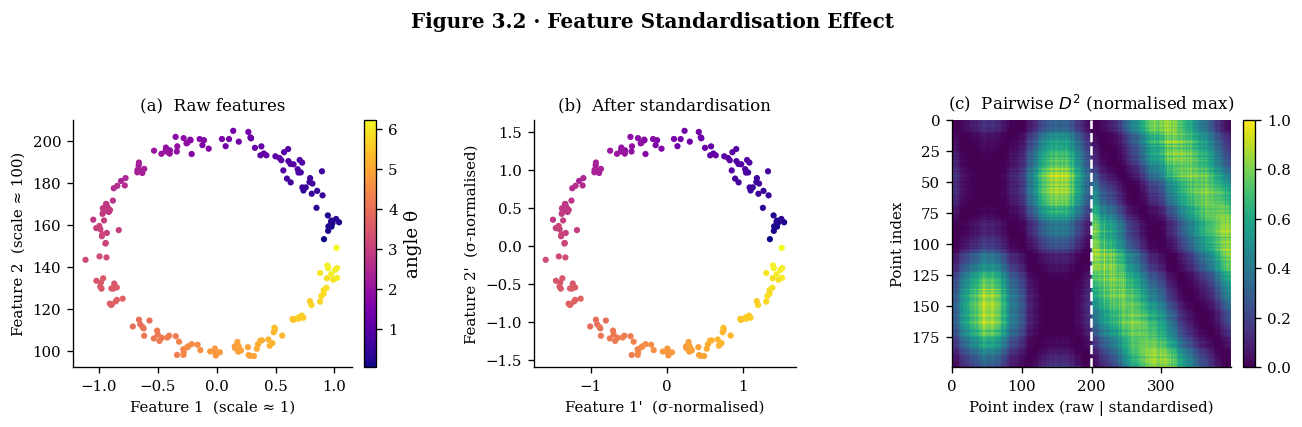

Saved: fig3_2_standardisation.pdf


In [10]:
# ── Fig 3.2 · Effect of standardisation ─────────────────────────
rng2 = np.random.default_rng(SEED)
n2   = 200

# Synthetic two-feature dataset: feature 1 in [0,1], feature 2 in [0,100]
theta = rng2.uniform(0, 2*np.pi, n2)
noise = rng2.normal(0, 0.05, (n2, 2))
X_raw = np.column_stack([
    np.cos(theta) + noise[:, 0],               # scale ~1
    (np.sin(theta) + noise[:, 1]) * 50 + 150,  # scale ~100
])

scaler = StandardScaler()
X_std  = scaler.fit_transform(X_raw)

D_raw = cdist(X_raw, X_raw, 'sqeuclidean')
D_std = cdist(X_std, X_std, 'sqeuclidean')

# Sort points by feature 1 for a cleaner distance-matrix visualisation
order = np.argsort(theta)
D_raw_s = D_raw[np.ix_(order, order)]
D_std_s = D_std[np.ix_(order, order)]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
c_raw = theta[order]

# Panel (a): raw scatter
sc = axes[0].scatter(X_raw[order, 0], X_raw[order, 1],
                     c=c_raw, cmap='plasma', s=14, lw=0)
axes[0].set_xlabel('Feature 1  (scale ≈ 1)', fontsize=9)
axes[0].set_ylabel('Feature 2  (scale ≈ 100)', fontsize=9)
axes[0].set_title('(a)  Raw features', fontsize=10)
fig.colorbar(sc, ax=axes[0], label='angle θ', fraction=0.046, pad=0.04)

# Panel (b): standardised scatter
axes[1].scatter(X_std[order, 0], X_std[order, 1],
                c=c_raw, cmap='plasma', s=14, lw=0)
axes[1].set_xlabel("Feature 1'  (σ-normalised)", fontsize=9)
axes[1].set_ylabel("Feature 2'  (σ-normalised)", fontsize=9)
axes[1].set_title('(b)  After standardisation', fontsize=10)
axes[1].set_aspect('equal')

# Panel (c): distance matrices side-by-side as coloured strips
vmax = max(D_raw_s.max(), D_std_s.max())
im = axes[2].imshow(
    np.hstack([D_raw_s / D_raw_s.max(), D_std_s / D_std_s.max()]),
    aspect='auto', cmap='viridis', origin='upper'
)
axes[2].set_title('(c)  Pairwise $D^2$ (normalised max)', fontsize=10)
axes[2].set_xlabel('Point index (raw | standardised)', fontsize=9)
axes[2].set_ylabel('Point index', fontsize=9)
mid = n2
axes[2].axvline(mid - 0.5, color='white', lw=1.5, ls='--')
axes[2].text(n2*0.25, -12, 'Raw', ha='center', va='center',
             fontsize=8, color='white')
axes[2].text(n2*0.75 + n2, -12, 'Std', ha='center', va='center',
             fontsize=8, color='white')
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

fig.suptitle('Figure 3.2 · Feature Standardisation Effect', fontsize=12,
             fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig('pictures/fig3_2_standardisation.pdf', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: pictures/fig3_2_standardisation.pdf')

## 3.3 Graph Construction and Markov Normalisation

Given standardised data $X' \in \mathbb{R}^{n \times d}$, the graph construction proceeds in four steps.

**Step 1 — Squared Euclidean distances:**

$$d_{ij}^2 = \|x'_i - x'_j\|^2$$

**Step 2 — Gaussian affinity kernel:**

$$W_{ij} = \exp\!\left(-\frac{d_{ij}^2}{\varepsilon}\right)$$

where $\varepsilon > 0$ is the bandwidth hyperparameter.  Larger $\varepsilon$ connects more distant points; smaller $\varepsilon$ restricts edges to near-neighbours.

**Step 3 — Anisotropic density normalisation** (Coifman & Lafon, 2006):

$$\widetilde{W}_{ij} = \frac{W_{ij}}{q_i^\alpha \, q_j^\alpha}, \qquad q_i = \sum_j W_{ij}$$

The exponent $\alpha \in [0,1]$ controls how aggressively sampling density is removed.  
Setting $\alpha = 1$ fully eliminates density bias; $\alpha = 0$ leaves $W$ unchanged.

**Step 4 — Row normalisation → Markov operator:**

$$P_{ij} = \frac{\widetilde{W}_{ij}}{\displaystyle\sum_k \widetilde{W}_{ik}}$$

Each row of $P$ sums to one, making it a stochastic transition matrix encoding one step of a random walk on the data graph.

**Figure 3.3** visualises the evolution of these four matrices on 60 points sampled from a half-moon curve, sorted by their arc-length position to reveal the block structure created by local connectivity.

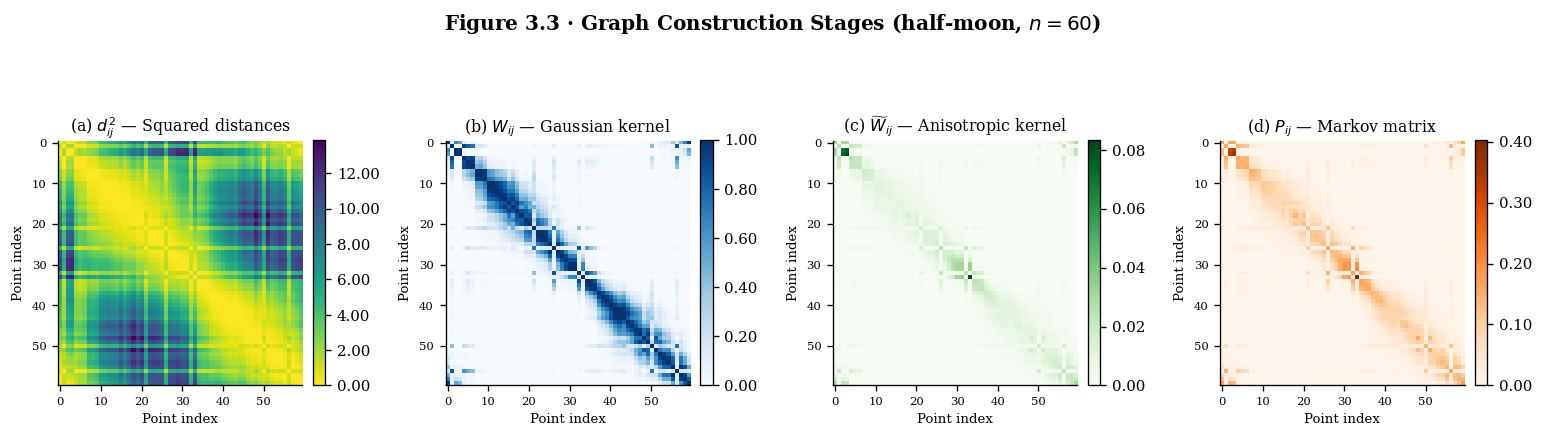

Saved: fig3_3_graph_construction.pdf


In [11]:
# ── Fig 3.3 · Step-by-step graph construction heatmaps ──────────
rng3  = np.random.default_rng(SEED)
n3    = 60
eps3  = 0.5
alpha = 1.0

X3, _ = make_moons(n_samples=n3, noise=0.06, random_state=SEED)
X3    = StandardScaler().fit_transform(X3)

# Sort by angle around origin for cleaner block structure
angles = np.arctan2(X3[:, 1], X3[:, 0])
order3 = np.argsort(angles)
Xo     = X3[order3]

D2_m = cdist(Xo, Xo, 'sqeuclidean')
W_m  = np.exp(-D2_m / eps3)

q_m      = W_m.sum(axis=1)
Wt_m     = W_m / np.outer(q_m**alpha, q_m**alpha)
P_m      = Wt_m / Wt_m.sum(axis=1, keepdims=True)

matrices  = [D2_m, W_m, Wt_m, P_m]
titles    = [
    r'(a) $d_{ij}^2$ — Squared distances',
    r'(b) $W_{ij}$ — Gaussian kernel',
    r'(c) $\widetilde{W}_{ij}$ — Anisotropic kernel',
    r'(d) $P_{ij}$ — Markov matrix',
]
cmaps = ['viridis_r', 'Blues', 'Greens', 'Oranges']

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))

for ax, mat, title, cmap_ in zip(axes, matrices, titles, cmaps):
    im = ax.imshow(mat, aspect='equal', cmap=cmap_, origin='upper',
                   vmin=0, vmax=mat.max())
    ax.set_title(title, fontsize=9.5, pad=5)
    ax.set_xlabel('Point index', fontsize=8)
    ax.set_ylabel('Point index', fontsize=8)
    ax.tick_params(labelsize=7)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, format='%.2f')

fig.suptitle('Figure 3.3 · Graph Construction Stages (half-moon, $n=60$)',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig('pictures/fig3_3_graph_construction.pdf', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: pictures/fig3_3_graph_construction.pdf')

## 3.4 Spectral Computation and Embedding Construction

Once the Markov matrix $P$ is formed, the embedding is constructed from its eigendecomposition.

Because $P$ is generally asymmetric, it is conjugated to the symmetric matrix

$$M = D^{1/2} P D^{-1/2}, \qquad D = \operatorname{diag}(\widetilde{W}\mathbf{1}),$$

whose real eigenvalues $1 = \lambda_0 \ge \lambda_1 \ge \cdots \ge \lambda_{n-1} \ge -1$ can be found by standard symmetric solvers.  The trivial mode $\lambda_0 = 1$ (uniform distribution) is discarded.

The **diffusion coordinates** at time $t$ are assembled from the leading $m$ non-trivial eigenpairs:

$$\Psi_t(x_i) = \bigl(\lambda_1^t\,\psi_1(i),\; \lambda_2^t\,\psi_2(i),\; \ldots,\; \lambda_m^t\,\psi_m(i)\bigr) \in \mathbb{R}^m$$

**Choosing $m$:** The eigenvalue spectrum typically exhibits a *spectral gap* — a sudden drop that separates informative modes from noise modes.  A practical heuristic is to retain all $\lambda_k$ with $\lambda_k / \lambda_1 > \tau$ for some threshold $\tau \in (0.05, 0.2)$.

**Figure 3.4** shows the eigenvalue spectrum for a Swiss Roll dataset, annotating the spectral gap and the retained two-dimensional subspace.

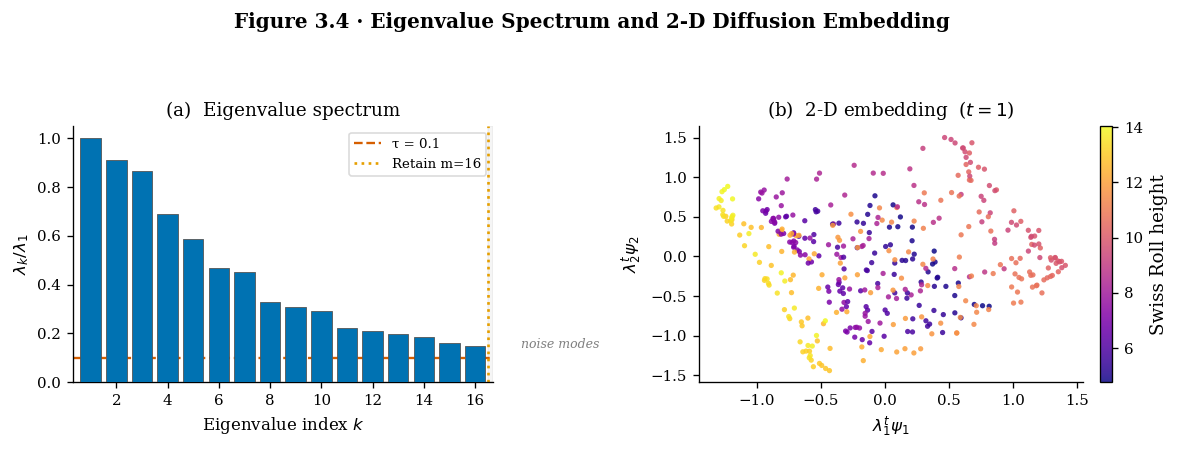

Retained 16 modes (τ=0.1).  Saved: fig3_4_eigenspectrum.pdf


In [12]:
# ── Fig 3.4 · Eigenvalue spectrum with spectral gap ─────────────
n4    = 400
eps4  = 2.0
t4    = 1
tau   = 0.10   # relative threshold for retaining modes

X4_raw, colour4 = make_swiss_roll(n_samples=n4, noise=0.3, random_state=SEED)
X4 = StandardScaler().fit_transform(X4_raw)

vals4, psi4, P4, W4, Wt4, _ = build_diffusion_map(X4, epsilon=eps4,
                                                    alpha=1.0, n_components=16)

# Normalise relative to leading eigenvalue
vals_rel = vals4 / vals4[0]
gap_idx  = np.argmax(np.diff(vals_rel) < 0) + 1   # first big drop
m_retain = np.sum(vals_rel >= tau)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

# Panel (a): spectrum bar chart
ks = np.arange(1, len(vals4) + 1)
colours_bar = [CB['blue'] if k <= m_retain else '#CCCCCC' for k in ks]
axes[0].bar(ks, vals_rel, color=colours_bar, edgecolor='#555', linewidth=0.5, zorder=3)
axes[0].axhline(tau, color=CB['vermilion'], lw=1.4, ls='--', label=f'τ = {tau}')
axes[0].axvline(m_retain + 0.5, color=CB['orange'], lw=1.6, ls=':', label=f'Retain m={m_retain}')
axes[0].set_xlabel('Eigenvalue index $k$', fontsize=10)
axes[0].set_ylabel(r'$\lambda_k / \lambda_1$', fontsize=10)
axes[0].set_title('(a)  Eigenvalue spectrum', fontsize=11)
axes[0].legend(fontsize=8, framealpha=0.7)
axes[0].set_xlim(0.3, len(vals4) + 0.7)

# Annotate spectral gap region
axes[0].axvspan(m_retain + 0.5, len(vals4) + 0.7, alpha=0.08, color='grey',
                label='noise modes')
axes[0].text(m_retain + 1.8, tau + 0.04, 'noise modes', fontsize=7.5,
             color='grey', style='italic')

# Panel (b): 2-D embedding coloured by Swiss Roll height
sc4 = axes[1].scatter(psi4[:, 0] * vals4[0]**t4,
                      psi4[:, 1] * vals4[1]**t4,
                      c=colour4, cmap='plasma', s=10, lw=0, alpha=0.85)
axes[1].set_xlabel(r'$\lambda_1^t \psi_1$', fontsize=10)
axes[1].set_ylabel(r'$\lambda_2^t \psi_2$', fontsize=10)
axes[1].set_title(f'(b)  2-D embedding  ($t={t4}$)', fontsize=11)
fig.colorbar(sc4, ax=axes[1], label='Swiss Roll height', fraction=0.046, pad=0.04)

fig.suptitle('Figure 3.4 · Eigenvalue Spectrum and 2-D Diffusion Embedding',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig('pictures/fig3_4_eigenspectrum.pdf', dpi=300, bbox_inches='tight')
plt.show()
print(f'Retained {m_retain} modes (τ={tau}).  Saved: fig3_4_eigenspectrum.pdf')

## 3.5 Hyperparameter Strategy

The Diffusion Map algorithm exposes four hyperparameters.  Their roles and recommended selection strategies are summarised below.

| Parameter | Symbol | Role | Selection guideline |
|---|---|---|---|
| Bandwidth | $\varepsilon$ | Controls affinity locality | Median heuristic: $\varepsilon^* = \operatorname{median}(d_{ij}^2)$; tune in $[\varepsilon^*/4,\; 4\varepsilon^*]$ |
| Density exponent | $\alpha$ | Removes sampling-density bias | $\alpha=1$ (geometry-only) is default; $\alpha=0$ for density-sensitive tasks |
| Diffusion time | $t$ | Scales eigenvalue contributions | $t=1$ for fine manifold detail in this setup; larger $t$ emphasises coarser structure |
| Embedding dim. | $m$ | Number of retained coordinates | Spectral-gap heuristic: retain $\lambda_k/\lambda_1 \ge \tau \approx 0.05$–$0.2$ |

### Effect of Diffusion Time $t$

Raising $t$ multiplies each diffusion coordinate by $\lambda_k^t$.  Because $|\lambda_k| < 1$ for $k \ge 1$, higher-index coordinates decay faster, progressively contracting the embedding toward clusters defined by the slowest-mixing modes.

**Figure 3.5** shows the two-dimensional Swiss Roll embedding at $t = 1, 4, 16$, illustrating that small $t$ values retain more fine-scale structure while large $t$ values increasingly contract the embedding.

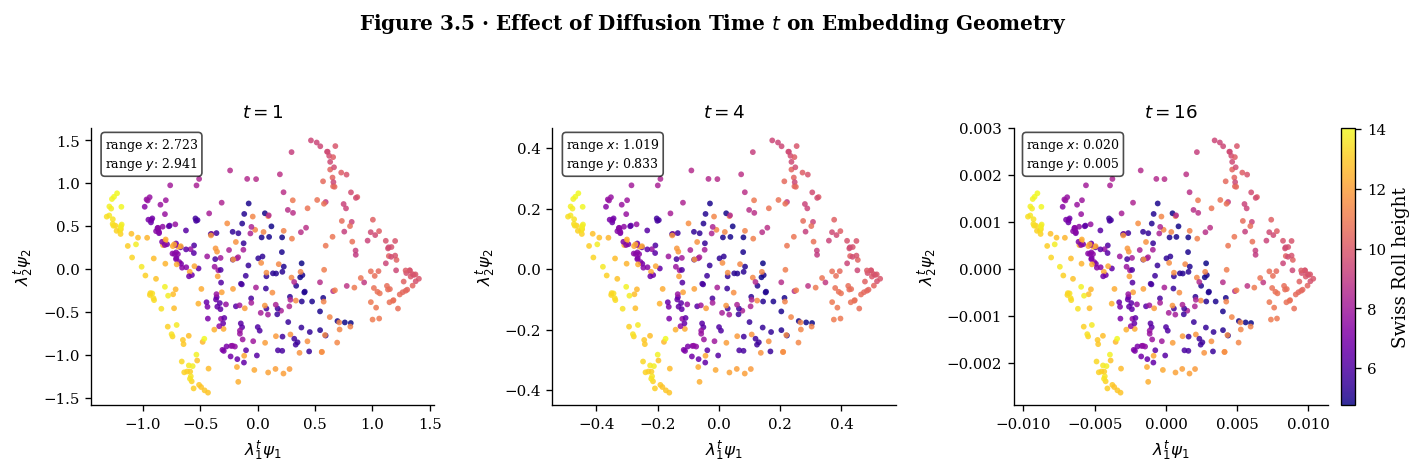

Saved: fig3_5_diffusion_time.pdf


In [13]:
# ── Fig 3.5 · Diffusion time effect: t = 1, 4, 16 ───────────────
n5  = 400
eps5 = 2.0

X5_raw, colour5 = make_swiss_roll(n_samples=n5, noise=0.3, random_state=SEED)
X5 = StandardScaler().fit_transform(X5_raw)

vals5, psi5, *_ = build_diffusion_map(X5, epsilon=eps5, alpha=1.0, n_components=8)

t_values = [1, 4, 16]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.0))

for ax, t in zip(axes, t_values):
    coords_x = psi5[:, 0] * vals5[0]**t
    coords_y = psi5[:, 1] * vals5[1]**t
    sc = ax.scatter(coords_x, coords_y,
                    c=colour5, cmap='plasma', s=12, lw=0, alpha=0.85)
    ax.set_xlabel(r'$\lambda_1^t \psi_1$', fontsize=10)
    ax.set_ylabel(r'$\lambda_2^t \psi_2$', fontsize=10)
    ax.set_title(f'$t = {t}$', fontsize=11)

    # Annotate range compression
    rx = coords_x.ptp()
    ry = coords_y.ptp()
    ax.text(0.04, 0.97, f'range $x$: {rx:.3f}\nrange $y$: {ry:.3f}',
            transform=ax.transAxes, fontsize=7.5, va='top',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7))

fig.colorbar(sc, ax=axes[-1], label='Swiss Roll height', fraction=0.046, pad=0.04)

fig.suptitle('Figure 3.5 · Effect of Diffusion Time $t$ on Embedding Geometry',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig('pictures/fig3_5_diffusion_time.pdf', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: pictures/fig3_5_diffusion_time.pdf')

## 3.6 Comparative Evaluation Protocol

To evaluate the Diffusion Map against classical alternatives (PCA and t-SNE), a controlled protocol is adopted:

1. **Shared data:** all methods receive the same standardised matrix $X'$ and the same random seed.  
2. **Fixed dimensionality:** every method reduces to the same target dimension (2-D for visualisation, 3-D for quantitative evaluation).  
3. **No supervised tuning:** hyperparameters are set by principled rules (median heuristic for $\varepsilon$; default perplexity 30 for t-SNE; full variance for PCA) before looking at results.  
4. **Evaluation metrics:** intrinsic dimensionality recovery is judged by (a) visual cluster separation, (b) continuity of colour gradients encoding known latent variables, and (c) retained nearest-neighbour rank correlation (Spearman $\rho$ between pairwise distances in the original space and in the embedding).

### Fairness Constraints

| Constraint | Reason |
|---|---|
| Same pre-processing for all methods | Prevents confounding standardisation benefit with algorithmic advantage |
| PCA retains $m$ components with maximal variance | Ensures PCA is used optimally, not handicapped |
| t-SNE uses Barnes–Hut with `perplexity=30` | Standard academic default; avoids cherry-picking perplexity |
| Diffusion Map uses $\varepsilon = \varepsilon^*_{\text{median}}$, $\alpha=1$, $t=1$ | Reproducible, principled baseline |

---

## 3.7 Computational Considerations

The na&iuml;ve implementation used in this study has the following complexity:

| Stage | Time complexity | Space complexity |
|---|---|---|
| Distance matrix $D^2$ | $\mathcal{O}(n^2 d)$ | $\mathcal{O}(n^2)$ |
| Kernel matrix $W$ | $\mathcal{O}(n^2)$ | $\mathcal{O}(n^2)$ |
| Dense eigen-decomp. | $\mathcal{O}(n^3)$ | $\mathcal{O}(n^2)$ |
| **Total** | $\mathbf{\mathcal{O}(n^2 d + n^3)}$ | $\mathbf{\mathcal{O}(n^2)}$ |

For the experiment sizes used here ($n \le 2000$, $d \le 3$), runtime is under a few seconds on a standard workstation.  
For $n > 10^4$, sparse alternatives are required:

- **Landmark Diffusion Maps** (de la Porte *et al.*, 2008): subsample $l \ll n$ landmark points; approximate the full embedding by Nyström extension.  
- **Sparse kernel graph**: threshold $W_{ij} < \delta_{\min}$ to zero; use sparse eigen-solvers (ARPACK/LOBPCG).  
- **Fast multipole methods**: reduce distance computation to $\mathcal{O}(n \log n)$.

These extensions are beyond the scope of the present study but are noted for completeness.

---

## 3.8 Chapter Summary

This chapter has established the complete experimental methodology:

- **Pre-processing:** z-score standardisation with numerical guard $\delta = 10^{-8}$.  
- **Graph construction:** Gaussian kernel → anisotropic normalisation ($\alpha = 1$) → Markov matrix.  
- **Spectral embedding:** symmetric eigendecomposition, spectral-gap truncation at $\tau = 0.10$, diffusion time $t = 1$.  
- **Comparative framework:** PCA and t-SNE evaluated under identical conditions.  
- **Reproducibility:** fixed seed, vector PDF outputs, open-source Python stack.

Chapter 4 applies this protocol to two benchmark datasets (Swiss Roll and two-moons) and reports quantitative and qualitative results.